In [1]:

import pandas as pd
import numpy as np
import seaborn as sns 
import matplotlib as plt


In [2]:
amazon_df = pd.read_csv(r"C:\Users\yagoc\Downloads\archive\amz_uk_price_prediction_dataset.csv")

In [3]:
num = amazon_df.select_dtypes(include="number")
cat = amazon_df.select_dtypes(exclude="number")

In [4]:
cat.columns

Index(['asin', 'title', 'isBestSeller', 'category'], dtype='object')

In [5]:
cate_ama = cat["category"]
isBest_ama = cat["isBestSeller"]

In [11]:
cross_counts = pd.crosstab(cat["category"], cat["isBestSeller"])

cross_counts

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [ ]:
proportions = pd.crosstab(cat["category"], cat["isBestSeller"], normalize='index')
proportions

isBestSeller,False,True
category,,
3D Printers,0.995968,0.004032
3D Printing & Scanning,0.999508,0.000492
Abrasive & Finishing Products,0.980000,0.020000
Action Cameras,0.999411,0.000589
Adapters,0.988189,0.011811
...,...,...
Wind Instruments,0.972000,0.028000
Window Treatments,0.979079,0.020921
Women,0.988015,0.011985


In [ ]:
result = pd.concat([cross_counts, proportions], keys=['Counts', 'Proportions'])
result


isBestSeller                                      False     True 
            category                                             
Counts      3D Printers                      247.000000  1.000000
            3D Printing & Scanning          4065.000000  2.000000
            Abrasive & Finishing Products    245.000000  5.000000
            Action Cameras                  1696.000000  1.000000
            Adapters                         251.000000  3.000000
...                                                 ...       ...
Proportions Wind Instruments                   0.972000  0.028000
            Window Treatments                  0.979079  0.020921
            Women                              0.988015  0.011985
            Women's Sports & Outdoor Shoes     0.989791  0.010209
            eBook Readers & Accessories        1.000000  0.000000

[592 rows x 2 columns]

In [ ]:
best_seller_rates = proportions[True].sort_values(ascending=False)
print("Categories ranked by best seller rate:")
display(best_seller_rates)

Categories ranked by best seller rate:


category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
                                    ...   
Power Supplies                    0.000000
Ski Helmets                       0.000000
Ski Goggles                       0.000000
Snowboard Boots                   0.000000
eBook Readers & Accessories       0.000000
Name: True, Length: 296, dtype: float64

In [ ]:

from scipy.stats import chi2_contingency

In [ ]:
_, chi2_pvalue, _, _ = chi2_contingency(cross_counts)

float(chi2_pvalue)

0.0

### · From such a small p-value, we can conclude that our variables HAVE statistical relationship between them

In [ ]:

from scipy.stats.contingency import association

association(cross_counts, method="cramer")

0.1222829439760564

### · So, as we can see, the two cateogries have in fact an association, but, from crarmer's value we can conclude it's not a super stron assocaition

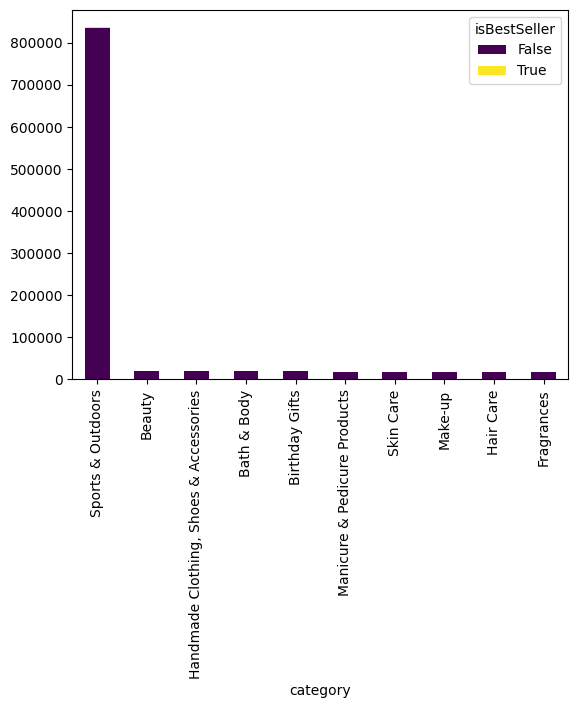

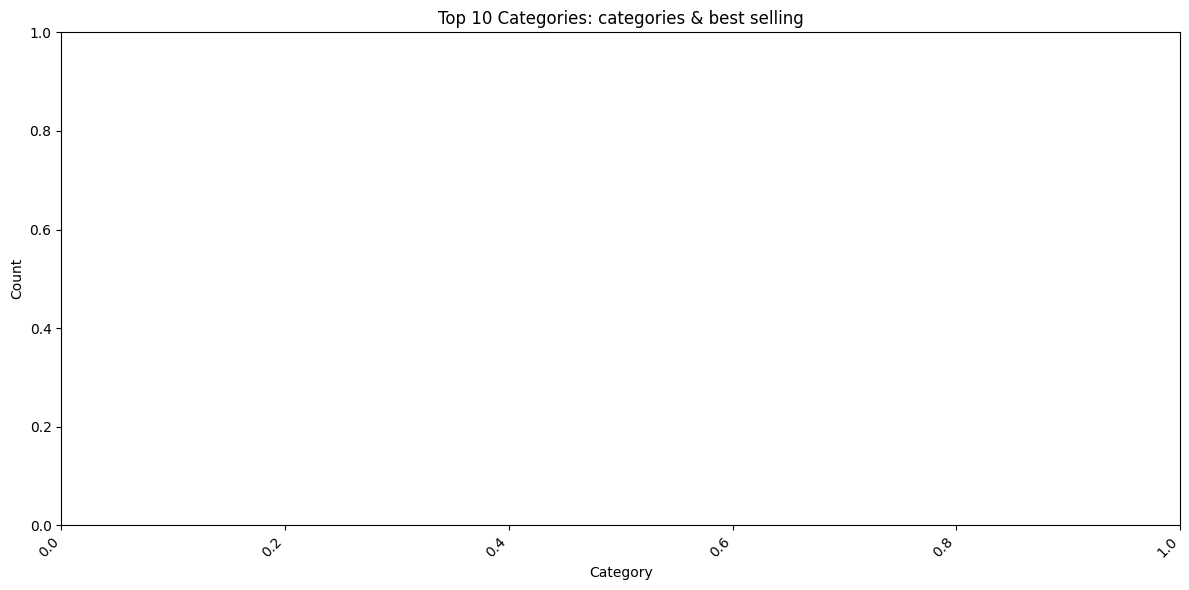

In [86]:
top_categories = cross_counts.sum(axis=1).nlargest(10)
top_cross_counts = cross_counts.loc[top_categories.index]

import matplotlib.pyplot as plt

top_cross_counts.plot(kind="bar", stacked=True, colormap="viridis")
plt.figure(figsize=(12,6))
plt.title("Top 10 Categories: categories & best selling")
plt.xlabel("Category")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [24]:
amazon_df["price"].describe().round(2)

count    2443651.00
mean          89.24
std          345.61
min            0.00
25%            9.99
50%           19.09
75%           45.99
max       100000.00
Name: price, dtype: float64

In [28]:
amazon_df["price"].median()

np.float64(19.09)

In [38]:
def clean_data_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR 

    clean_data = data[(data >= lower) | (data <= upper)]

    return clean_data

amazon_prices_cleared = clean_data_outliers(amazon_df["price"])

amazon_prices_cleared



0          21.99
1          23.99
2          21.99
3          31.99
4          17.99
           ...  
2443646    22.34
2443647    97.99
2443648    52.99
2443649    79.99
2443650    53.99
Name: price, Length: 2443651, dtype: float64

In [ ]:
amazon_top_20 = amazon_df.loc[amazon_prices_cleared.index, "category"].value_counts().head(20).index

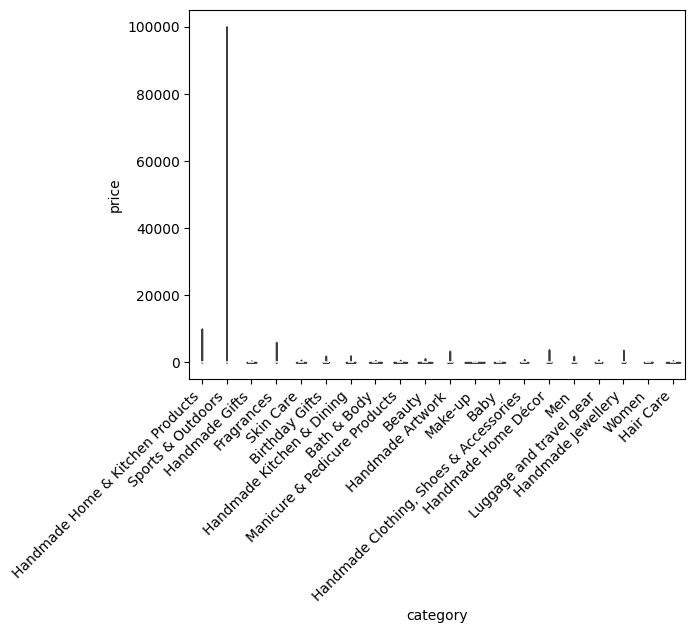

In [54]:
# Filter the DataFrame for the top 10 categories
df_top_20 = amazon_df[amazon_df["category"].isin(amazon_top_20)]


sns.violinplot(data=df_top_20, x="category", y="price")
plt.xticks(rotation=45, ha="right")
plt.show()

In [59]:
median_by_category = amazon_df.groupby('category')['price'].median().sort_values(ascending=False)
median_by_category

category
Laptops                      1042.725
Desktop PCs                   810.400
Snowboards                    366.725
Home Audio Record Players     326.080
3D Printers                   319.000
                               ...   
Adapters                        7.050
Make-up                         7.000
Signs & Plaques                 6.990
Arts & Crafts                   5.990
Office Paper Products           4.380
Name: price, Length: 296, dtype: float64

### The category with the highest median in all amazon dataframe are: laptops

In [ ]:
amazon_top_10 = amazon_df.loc[amazon_prices_cleared.index, "category"].value_counts().head(10).index

df_top_10 = amazon_df[amazon_df["category"].isin(amazon_top_10)]


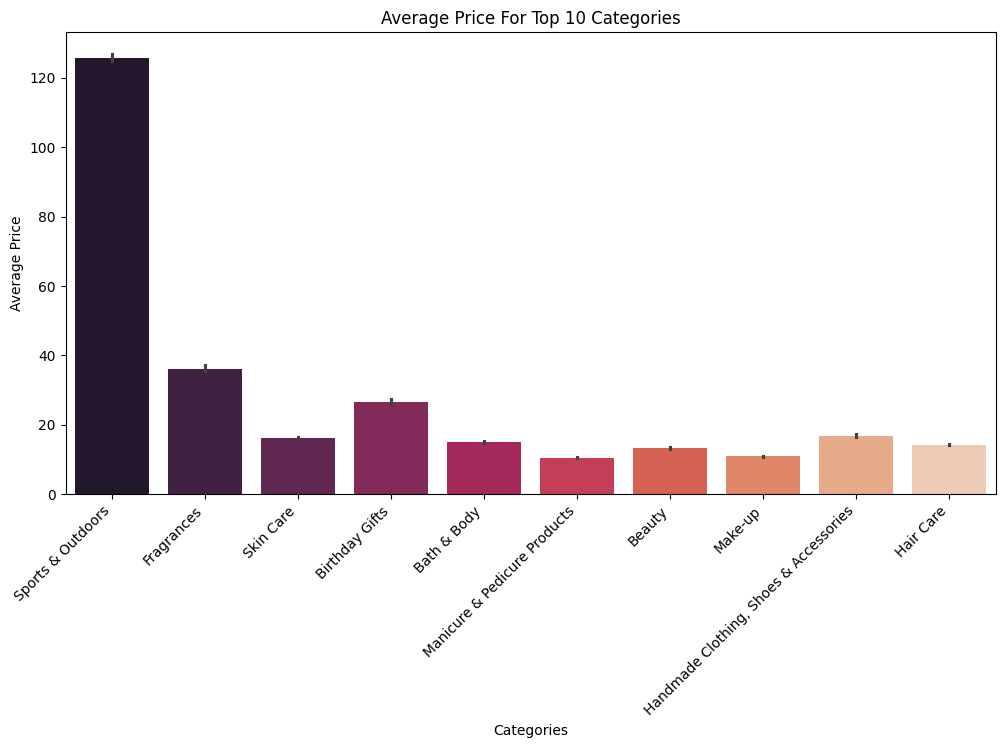

In [72]:
plt.figure(figsize=(12,6))
sns.barplot(data=df_top_10, x="category", y="price", hue="category", palette="rocket", legend=False)
plt.title("Average Price For Top 10 Categories")
plt.xlabel("Categories")
plt.ylabel("Average Price")
plt.xticks(rotation=45, ha="right")
plt.show()

In [67]:
mean_by_category = amazon_df.groupby("category")["price"].mean().sort_values(ascending=False)

mean_by_category

category
Laptops                  1087.987827
3D Printers              1018.036129
Desktop PCs               926.816064
Home Office Furniture     622.135898
Test & Measurement        559.382973
                            ...     
Bedding Accessories         8.835220
Adapters                    8.750197
Signs & Plaques             8.275136
Arts & Crafts               8.182523
Office Paper Products       7.047684
Name: price, Length: 296, dtype: float64

### With filtered categories, sports and outdoors are the most high average price in the dataframe, nevertheless, with filtered categories, the highest average price are still laptops 

In [ ]:
rating_by_category = amazon_df.groupby("category")["stars"]



C:\Users\yagoc\AppData\Local\Temp\ipykernel_8056\3389068959.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top_10, x="category", y="stars", palette= "mako")


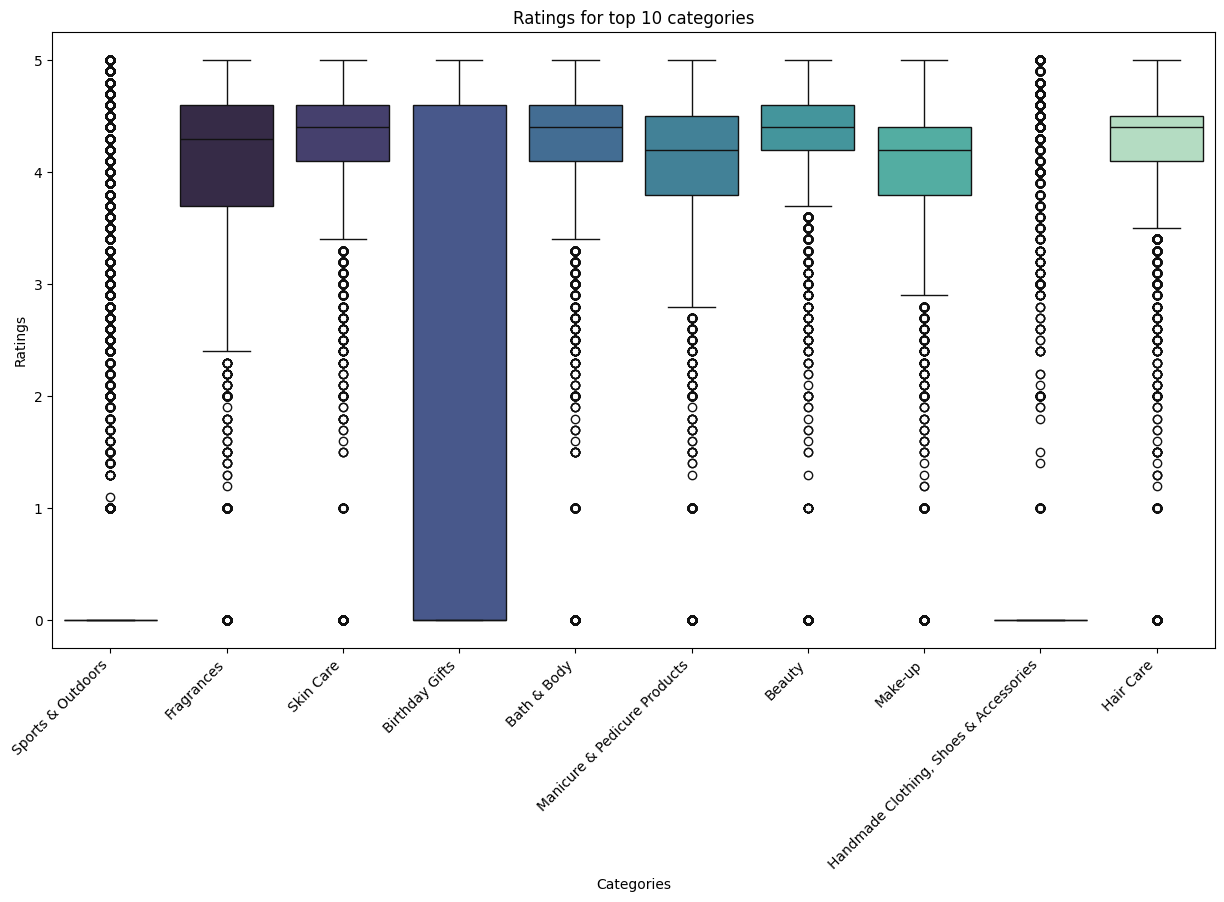

In [84]:
plt.figure(figsize=(15,8))
sns.boxplot(data=df_top_10, x="category", y="stars", palette= "mako")
plt.title("Ratings for top 10 categories")
plt.xlabel("Categories")
plt.ylabel("Ratings")
plt.xticks(rotation=45, ha="right")
plt.show()

In [ ]:
###